# Entrega 3 · Modelado

* **Grupo:** Grupo 7
* **Integrantes:** Nicolás López · Felipe Haudet · Franco Sorrentino · Facundo Caiña · Lucca Burgos
* **Pregunta del proyecto:** ¿Qué factores influyen para que un jugador llegue a un club top 20 de Europa?
* **Variable objetivo:** `es_destino_top_20`: el club de destino está entre los 20 primeros del
  coeficiente de clubes de UEFA. Es una **clasificación binaria**.

## 0 · Qué cambió desde la Entrega 2

1. **`score_posicion` no entra al modelo.** Como una sola columna, la predicción dependía sólo de si
   ese número era alto o bajo. Entran sus componentes: cada estadística normalizada **dentro de su
   rol** (`z_goals`, `z_tackles`, ...) más `grupo_posicion`. La normalización ahora se aprende
   adentro del pipeline, sólo con el entrenamiento.
2. **Hipótesis 5, sobre el club de origen.** Confirmada fuera de las ligas top 5, y casi sin
   correlación con el rendimiento (0,18): el bloque del club de origen se queda.
3. **Fichajes con las estadísticas de otro jugador.** La media de goles de los arqueros daba 0,7,
   y no era fútbol: el cruce con FotMob es por nombre, y a algunos arqueros les tocaron las
   estadísticas de un jugador de campo con el mismo nombre (Matheus del Braga con 15 goles, que
   eran de un delantero). Salen los fichajes donde Transfermarkt y FotMob no coinciden en si el
   jugador es arquero.

### Y lo que corregimos después de la devolución

4. **El barrido va antes de elegir.** Antes comparábamos las cuatro familias con sus valores por
   defecto y ajustábamos sólo la ganadora. Ahora cada familia se ajusta con su grilla y recién después
   se comparan, cada una en su mejor versión (Sección 5). Con eso cambia el modelo elegido.
5. **La edad entra numérica.** La cortábamos en tramos a mano; ahora entra en años y cada modelo
   aprende su forma solo. Agregamos a la Entrega 2 la hipótesis que faltaba, la 6, sobre la edad: sola
   separa poco, pero pesa cruzada con la liga de origen y con los minutos.
6. **La precision.** Medimos precision y recall en cada comparación y probamos varias formas de
   subirla: el barrido, más columnas, menos columnas y el umbral (Secciones 5 y 7).
7. **Los errores, explicados.** Un gráfico de por qué se equivoca, y los falsos positivos (los que el
   modelo cree que debería haber comprado un club grande) y los falsos negativos, con nombres
   (Sección 8). El modelo elegido no tiene coeficientes, así que en qué se apoya se mide con la
   importancia por permutación (Sección 9).

## 1 · Carga y población

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

SEMILLA = 42

df = pd.read_csv("fichajes.csv", low_memory=False)
print(f"{len(df):,} fichajes x {df.shape[1]} columnas")

13,063 fichajes x 107 columnas


Lo que sigue es lo mismo que la Entrega 2: el puesto agrupado en 7 roles, y la población de análisis
(`ana`), que son los fichajes **con estadísticas de la temporada anterior** y sin las promociones
internas (`tipo_operacion = desconocido`). Son recodificaciones fila por fila con un diccionario fijo:
no aprenden nada de los datos, así que pueden ir afuera del pipeline.

Y una limpieza nueva: se van los fichajes donde Transfermarkt y FotMob **no coinciden en si el
jugador es arquero**. Es un error del cruce por nombre (ver la Sección 0), y también es una regla fija.

In [2]:
GRUPOS_POSICION = {
    "Goalkeeper": "Arquero",
    "Centre-Back": "Defensor central", "Defender": "Defensor central",
    "Right-Back": "Lateral", "Left-Back": "Lateral",
    "Defensive Midfield": "Mediocampo defensivo",
    "Central Midfield": "Mediocampo ofensivo", "Attacking Midfield": "Mediocampo ofensivo",
    "Right Midfield": "Mediocampo ofensivo", "Left Midfield": "Mediocampo ofensivo",
    "Midfielder": "Mediocampo ofensivo",
    "Centre-Forward": "Delantero centro", "Second Striker": "Delantero centro",
    "Striker": "Delantero centro",
    "Left Winger": "Delantero extremo", "Right Winger": "Delantero extremo",
}
df["grupo_posicion"] = df["posicion_tm"].map(GRUPOS_POSICION)
df["stat_goals_conceded_inv"] = -pd.to_numeric(df["stat_goals_conceded"], errors="coerce")

# puntos FIFA promedio 2016-2026 de la selección (Hipótesis 1): una tabla externa, sin el objetivo
fifa = pd.read_csv("ranking_fifa.csv")
canon = fifa.sort_values("year").groupby("country_code")["country_name"].last()
puntos = fifa.groupby("country_code")["total_points"].mean()
nombre_a_codigo = {nombre: codigo for codigo, nombre in canon.items()}
nombre_a_codigo.update({
    "Bosnia-Herzegovina": "BIH", "Cape Verde": "CPV", "China": "CHN", "Cote d'Ivoire": "CIV",
    "Curacao": "CUW", "Czech Republic": "CZE", "DR Congo": "COD", "Iran": "IRN", "Ireland": "IRL",
    "Korea, South": "KOR", "Sao Tome and Principe": "STP", "Southern Sudan": "SSD",
    "United States": "USA"})
df["fifa_puntos_prom"] = df["nacionalidad"].map(nombre_a_codigo).map(puntos)

con_historial = df["tiene_historial"].astype("boolean").fillna(False)
poblacion = con_historial & df["tipo_operacion"].ne("desconocido")

# el cruce con FotMob es por nombre, y a veces pega las stats de otro jugador que se llama igual
# (al arquero Neto del Bournemouth le tocaron las de un extremo llamado Neto). Si Transfermarkt
# y FotMob no coinciden en si el jugador es arquero, el cruce está mal y la fila sale.
arquero_tm = df["posicion_tm"].eq("Goalkeeper")
arquero_fotmob = df["posicion_fotmob"].str.lower().eq("keeper")
cruce_roto = arquero_tm != arquero_fotmob
print(f"fichajes con el cruce roto: {(poblacion & cruce_roto).sum()} "
      f"({(poblacion & cruce_roto & arquero_tm).sum()} arqueros con stats de jugador de campo, "
      f"{(poblacion & cruce_roto & ~arquero_tm).sum()} al revés)")

ana = df[poblacion & ~cruce_roto].reset_index(drop=True)

print(f"población de análisis: {len(ana):,} fichajes, {ana['jugador_tm_id'].nunique():,} jugadores")
print(f"positivos (destino top 20): {int(ana['es_destino_top_20'].sum())} = {ana['es_destino_top_20'].mean():.2%}")

fichajes con el cruce roto: 27 (13 arqueros con stats de jugador de campo, 14 al revés)
población de análisis: 7,410 fichajes, 5,279 jugadores
positivos (destino top 20): 761 = 10.27%


## 2 · El planteo

Cuatro decisiones antes del primer modelo, porque todo lo demás se lee contra ellas.

### 2.1 Qué predecimos y con qué columnas

Predecimos `es_destino_top_20` **justo antes del fichaje**: sabemos quién es el jugador, de dónde
viene y cómo le fue la temporada pasada. Las columnas son las que la tabla de la Entrega 2 dejó
entrar, con el cambio de la Sección 0:

| Bloque | Columnas | Cómo entran |
|---|---|---|
| Rendimiento | las 23 `stat_*` que arman `score_posicion` | z dentro de su rol; sin dato → 0 (el promedio del rol) |
| Rol | `grupo_posicion` | one-hot |
| Club de origen | coeficiente UEFA del club y del país | log, sin dato → 0 más una columna «no está en el ranking» |
| Club de origen | liga top 5, filial, europeo | 0 / 1 |
| Jugador | `edad_al_fichaje` | numérica, en años: cada modelo aprende su forma (Hipótesis 6) |
| Control | `temporada_fichaje` | one-hot |

Todo lo que se fue por fuga en la Entrega 2 (club de destino, monto, tipo de operación, salto de
ranking) sigue afuera. Además quedan aparte, para probarlas en la Sección 7, `fifa_puntos_prom` y cuatro
candidatas de la tabla de la Entrega 2 que no habían entrado: si el club de origen es top 20 o top 50
de UEFA, la liga de origen y la nacionalidad.

In [3]:
BASE = ["stat_minutes", "stat_matches"]
ESPECIFICAS = {
    "Arquero": ["stat_saves", "stat_save_percentage", "stat_goals_conceded_inv",
                "stat_goals_prevented", "stat_high_claims"],
    "Defensor central": ["stat_tackles", "stat_interceptions", "stat_duels_won_%",
                          "stat_aerials_won_%", "stat_recoveries"],
    "Lateral": ["stat_tackles", "stat_interceptions", "stat_duels_won_%",
                "stat_successful_crosses", "stat_recoveries"],
    "Mediocampo defensivo": ["stat_tackles", "stat_interceptions", "stat_duels_won_%",
                              "stat_recoveries", "stat_pass_accuracy"],
    "Mediocampo ofensivo": ["stat_pass_accuracy", "stat_chances_created", "stat_assists",
                             "stat_dribbles_success_rate", "stat_possession_won_final_3rd"],
    "Delantero centro": ["stat_goals", "stat_xg", "stat_shots_on_target",
                          "stat_touches_in_opposition_box", "stat_aerials_won_%"],
    "Delantero extremo": ["stat_goals", "stat_assists", "stat_dribbles_success_rate",
                           "stat_successful_crosses", "stat_big_chances_created"],
}
STATS = BASE + sorted({c for cols in ESPECIFICAS.values() for c in cols})

ORIGEN_LOG = ["club_origen_coeficiente_uefa", "club_origen_pais_coeficiente_uefa"]
SI_NO = ["club_origen_liga_es_top5", "club_origen_es_filial", "club_origen_es_europeo"]
CATEGORICAS = ["grupo_posicion", "temporada_fichaje"]
EDAD = ["edad_al_fichaje"]

# candidatas que se prueban en la Sección 7 (recodificaciones fijas, fila por fila)
ana["club_origen_liga"] = ana["club_origen_liga"].fillna("sin dato")
ana["tiene_segunda_nacionalidad"] = ana["nacionalidad_2"].notna()
CANDIDATAS = ["fifa_puntos_prom", "club_origen_es_top_20", "club_origen_es_top_50",
              "club_origen_liga", "nacionalidad", "tiene_segunda_nacionalidad"]
COLUMNAS_MODELO = STATS + ORIGEN_LOG + SI_NO + CATEGORICAS + EDAD

X = ana[COLUMNAS_MODELO + CANDIDATAS]
y = ana["es_destino_top_20"].astype(int)
jugador = ana["jugador_tm_id"]

print(f"{len(STATS)} stats + {len(ORIGEN_LOG) + len(SI_NO)} del origen + "
      f"{len(CATEGORICAS)} categóricas + edad  ({len(CANDIDATAS)} candidatas quedan aparte, para la Sección 7)")

23 stats + 5 del origen + 2 categóricas + edad  (6 candidatas quedan aparte, para la Sección 7)


### 2.2 La métrica: f1 macro

Con 10 % de positivos, la **accuracy** esconde a la clase chica: un modelo que contesta siempre «no
top 20» acierta el 90 %. El **f1 macro** promedia el f1 de las dos clases por igual, así que un modelo
que nunca dice «top 20» se queda en la mitad.

¿Qué error nos cuesta más? El modelo sirve para **señalar jugadores con perfil de club top 20**.
Perder a uno que sí llegó (falso negativo) y señalar a uno que no (falso positivo) cuestan parecido:
uno nos deja sin el jugador, el otro nos llena la lista de nombres que no van. Por eso el f1, que
castiga que **cualquiera** de los dos, precision o recall, sea bajo.

### 2.3 La partición: por jugador

Una fila es un fichaje, y hay jugadores con más de un fichaje en el período. Si el mismo jugador
queda en el entrenamiento y en el test, el modelo puede reconocerlo en vez de predecirlo. Por eso
los pedazos se arman **por jugador** con `StratifiedGroupKFold`: el mismo jugador nunca queda de los
dos lados, y cada pedazo conserva el 10 % de positivos.

El test es uno de esos cinco pedazos (20 %), y no se toca hasta la Sección 8. La validación cruzada
de todo lo demás usa la misma regla, adentro del entrenamiento.

In [4]:
from sklearn.model_selection import StratifiedGroupKFold

particion = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
idx_train, idx_test = next(particion.split(X, y, groups=jugador))

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
g_train = jugador.iloc[idx_train]

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

pd.DataFrame({"filas": [len(X_train), len(X_test)],
              "jugadores": [g_train.nunique(), jugador.iloc[idx_test].nunique()],
              "positivos": [y_train.mean(), y_test.mean()]},
             index=["entrenamiento", "test"]).round(3)

,filas,jugadores,positivos
entrenamiento,5928,4224,0.103
test,1482,1055,0.103


In [5]:
# el chequeo que justifica la partición: ningún jugador de los dos lados
print("jugadores en train y en test a la vez:", len(set(g_train) & set(jugador.iloc[idx_test])))

jugadores en train y en test a la vez: 0


### 2.4 El piso

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score

piso = DummyClassifier(strategy="most_frequent", random_state=SEMILLA)
f1_piso = cross_val_score(piso, X_train, y_train, groups=g_train, cv=cv, scoring="f1_macro")
print(f"piso (contesta siempre «no top 20»): f1 macro {f1_piso.mean():.3f} ± {f1_piso.std():.3f}")

piso (contesta siempre «no top 20»): f1 macro 0.473 ± 0.000


**0,473**: acierta todos los «no» y ninguno de los «sí», y el f1 macro lo deja en la mitad. Es el
número contra el que se lee todo lo que viene.

## 3 · El pipeline

En `fit`
aprende la media y el desvío de cada stat **por rol, sólo con el entrenamiento**; en `transform`
los aplica.

In [7]:
from sklearn.base import BaseEstimator, TransformerMixin


class ZPorRol(BaseEstimator, TransformerMixin):
    '''Cada stat pasa a z dentro del rol del jugador: (valor - media del rol) / desvío del rol.'''

    def __init__(self, columnas=(), rol="grupo_posicion"):
        self.columnas = columnas
        self.rol = rol

    def fit(self, X, y=None):
        valores = X[list(self.columnas)].apply(pd.to_numeric, errors="coerce")
        self.medias_ = valores.groupby(X[self.rol]).mean()
        self.desvios_ = valores.groupby(X[self.rol]).std().replace(0, np.nan)
        return self

    def transform(self, X):
        valores = X[list(self.columnas)].apply(pd.to_numeric, errors="coerce")
        media = self.medias_.reindex(X[self.rol]).set_index(X.index)
        desvio = self.desvios_.reindex(X[self.rol]).set_index(X.index)
        return ((valores - media) / desvio).rename(columns=lambda c: "z_" + c.removeprefix("stat_"))

    def get_feature_names_out(self, input_features=None):
        return np.array(["z_" + c.removeprefix("stat_") for c in self.columnas])


# lo que aprendió, sobre el entrenamiento: la media de goles por rol
ZPorRol(columnas=["stat_goals"]).fit(X_train).medias_.round(2)

,stat_goals
grupo_posicion,
Arquero,0.00
Defensor central,1.06
Delantero centro,8.01
Delantero extremo,4.71
Lateral,1.34
Mediocampo defensivo,1.57
Mediocampo ofensivo,3.40


In [8]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.base import clone


def a_numero(x):
    return x.astype(float)


def preparar(stats=STATS, origen=ORIGEN_LOG, si_no=SI_NO, extra=(), categoricas_extra=()):
    '''Una rama por tipo de columna. extra y categoricas_extra: lo que se prueba en la Sección 7.'''
    ramas = []
    if stats:
        ramas.append(("stats", Pipeline([("z", ZPorRol(columnas=tuple(stats))),
                                         ("imputar", SimpleImputer(strategy="constant", fill_value=0))]),
                      list(stats) + ["grupo_posicion"]))
    ramas += [
        ("edad", Pipeline([("imputar", SimpleImputer(strategy="median")),
                           ("escalar", StandardScaler())]), EDAD),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS)]
    if si_no:
        ramas.append(("si_no", FunctionTransformer(a_numero, feature_names_out="one-to-one"), list(si_no)))
    if origen:
        ramas.append(("origen", Pipeline([
            ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
            ("imputar", SimpleImputer(strategy="constant", fill_value=0, add_indicator=True)),
            ("escalar", StandardScaler())]), list(origen)))
    if extra:
        ramas.append(("extra", Pipeline([("imputar", SimpleImputer(strategy="median")),
                                         ("escalar", StandardScaler())]), list(extra)))
    if categoricas_extra:
        # las categorías con menos de 40 fichajes se juntan en una sola columna «otras»
        ramas.append(("categoricas_extra", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                         min_frequency=40), list(categoricas_extra)))
    return ColumnTransformer(ramas)


def armar(clasificador, **columnas):
    '''El pipeline completo con el clasificador que se le pase al final.'''
    return Pipeline([("preparar", preparar(**columnas)), ("clasificador", clasificador)])


from sklearn.linear_model import LogisticRegression

armar(LogisticRegression(max_iter=3000))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparar', ...), ('clasificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('stats', ...), ('edad', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, defaul

In [9]:
# cuántas columnas le llegan al clasificador
preparar().fit_transform(X_train, y_train).shape

(5928, 43)

## 4 · El desbalance: qué decidimos

Con 10 % de positivos, un modelo entrenado tal cual casi nunca dice «top 20»: `predict` contesta
«sí» sólo si la probabilidad pasa 0,5, y muy pocos fichajes llegan ahí. Las dos palancas posibles
son `class_weight="balanced"` (reentrenar pesando más a los positivos) o **mover el
umbral** (dejar el modelo como está y decir «top 20» desde una probabilidad más baja).

Son dos herramientas distintas para el mismo problema, así que las medimos **cada una por su
cuenta**, sin mezclarlas, y nos quedamos con la que da mejor f1 macro. Como todo lo que se elige, el
umbral **se elige por validación cruzada**: `cross_val_predict` da la probabilidad de cada fichaje del
entrenamiento calculada por el pedazo que no lo vio, y sobre eso se mide el f1 macro de cada umbral,
pedazo por pedazo.

In [10]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score, precision_score, recall_score

UMBRALES = np.round(np.arange(0.05, 0.80, 0.05), 2)


def por_umbral(modelo, X=None, validacion=cv):
    '''Para cada umbral: f1 macro (media y desvío entre los 5 pedazos), y precision y recall de «top 20».'''
    X = X_train if X is None else X
    pedazos = list(validacion.split(X, y_train, groups=g_train))
    proba = cross_val_predict(modelo, X, y_train, groups=g_train, cv=pedazos,
                              method="predict_proba", n_jobs=-1)[:, 1]
    filas = []
    for u in UMBRALES:
        f1s, precisiones, recalls = [], [], []
        for _, v in pedazos:
            real, dice = y_train.iloc[v], proba[v] >= u
            f1s.append(f1_score(real, dice, average="macro"))
            precisiones.append(precision_score(real, dice, zero_division=0))
            recalls.append(recall_score(real, dice))
        filas.append({"umbral": u, "f1 medio": np.mean(f1s), "desvío": np.std(f1s),
                      "precision": np.mean(precisiones), "recall": np.mean(recalls)})
    return pd.DataFrame(filas).set_index("umbral")


def medir(modelo, **kw):
    '''El resumen de por_umbral: el f1 con el umbral de siempre (0,5) y con el mejor, y su precision y recall.'''
    t = por_umbral(modelo, **kw)
    mejor = t["f1 medio"].idxmax()
    return {"f1 con umbral 0,5": t.loc[0.5, "f1 medio"], "desvío (0,5)": t.loc[0.5, "desvío"],
            "mejor umbral": mejor, "f1 con mejor umbral": t.loc[mejor, "f1 medio"],
            "desvío": t.loc[mejor, "desvío"], "precision": t.loc[mejor, "precision"],
            "recall": t.loc[mejor, "recall"]}


tabla_umbral = por_umbral(armar(LogisticRegression(max_iter=3000)))
tabla_umbral.round(3).T

umbral,0.05,0.10,0.15,0.20,0.25,0.30,0.35,0.40,0.45,0.50,0.55,0.60,0.65,0.70,0.75
f1 medio,0.500,0.609,0.654,0.671,0.663,0.657,0.643,0.625,0.613,0.598,0.579,0.557,0.538,0.533,0.515
desvío,0.007,0.005,0.008,0.007,0.018,0.024,0.021,0.018,0.010,0.015,0.021,0.022,0.023,0.021,0.020
precision,0.181,0.253,0.309,0.356,0.381,0.414,0.441,0.469,0.520,0.582,0.625,0.663,0.672,0.738,0.776
recall,0.880,0.762,0.645,0.532,0.418,0.353,0.287,0.230,0.192,0.158,0.126,0.095,0.071,0.064,0.044


In [11]:
# las dos palancas, cada una por su cuenta, sobre la regresión logística
sin_pesos = medir(armar(LogisticRegression(max_iter=3000)))
con_pesos = medir(armar(LogisticRegression(max_iter=3000, class_weight="balanced")))

pd.DataFrame({
    "nada (umbral 0,5)":                    {"f1 macro": sin_pesos["f1 con umbral 0,5"], "desvío": sin_pesos["desvío (0,5)"]},
    "class_weight='balanced' (umbral 0,5)": {"f1 macro": con_pesos["f1 con umbral 0,5"], "desvío": con_pesos["desvío (0,5)"]},
    f"mover el umbral (sin pesos, {sin_pesos['mejor umbral']:.2f})":
                                            {"f1 macro": sin_pesos["f1 con mejor umbral"], "desvío": sin_pesos["desvío"]},
}).T.round(3)

,f1 macro,desvío
"nada (umbral 0,5)",0.598,0.015
"class_weight='balanced' (umbral 0,5)",0.613,0.007
"mover el umbral (sin pesos, 0.20)",0.671,0.007


**Qué decidimos: mover el umbral.** El modelo da una probabilidad, y por defecto dice «top 20» sólo
si pasa 0,5. Como sólo el 10 % de los fichajes llega a un top 20, casi nadie pasa 0,5: con ese umbral
la regresión logística da **0,598**, apenas arriba del piso (0,473). Probamos umbrales más bajos con
validación cruzada (la primera tabla) y el mejor fue **0,20**, con f1 **0,671**. La misma tabla muestra
el precio: al bajar el umbral el recall sube y la precision baja.

La otra palanca, `class_weight="balanced"` con el umbral de siempre, da **0,613** (la segunda tabla):
mejora a la logística sin nada, pero queda lejos del umbral. La diferencia (0,058) es varias veces el
desvío, así que no es azar: **mover el umbral es claramente mejor**, y además es una sola regla que no
cambia el entrenamiento.

Acá la logística es sólo la referencia para decidir la regla: todavía no elegimos modelo. En la Sección
5 cada familia busca su propio umbral. Lo que costó se ve en el test (Sección 8): la accuracy queda
debajo de contestar siempre «no», y la precision es baja; por eso la Sección 7 prueba formas de subirla.

## 5 · El barrido y la comparación

Primero se ajusta cada familia, después se compara. Las cuatro familias —la regresión logística como
referencia, un árbol, un bosque y un boosting— pasan cada una por su grilla de hiperparámetros, todas
con las mismas columnas, la misma validación por jugador y la misma regla del umbral (`medir`). Así cada
familia compite en su mejor versión, y no con los valores que trae por defecto.

Las grillas son las de la Práctica 2, adaptadas: `C` para la logística; profundidad y tamaño mínimo de
hoja para el árbol; profundidad, hoja y cuántas columnas mira cada pregunta para el bosque; tasa de
aprendizaje, cantidad de árboles y hojas para el boosting. Se hace con un bucle y no con
`GridSearchCV` porque `GridSearchCV` mide con `predict`, es decir con el umbral fijo en 0,5.

In [12]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import ParameterGrid

FAMILIAS = {
    "regresión logística": (LogisticRegression(max_iter=3000), {"C": [0.01, 0.1, 1, 10]}),
    "árbol de decisión": (DecisionTreeClassifier(random_state=SEMILLA),
                          {"max_depth": [3, 5, 8, 12], "min_samples_leaf": [1, 20, 50]}),
    "random forest": (RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEMILLA),
                      {"max_depth": [None, 10], "min_samples_leaf": [1, 5, 20],
                       "max_features": ["sqrt", 0.3]}),
    "gradient boosting": (HistGradientBoostingClassifier(random_state=SEMILLA),
                          {"learning_rate": [0.03, 0.1], "max_iter": [100, 300],
                           "max_leaf_nodes": [15, 31]}),
}

barrido = []
for familia, (modelo, grilla) in FAMILIAS.items():
    for params in ParameterGrid(grilla):
        barrido.append({"familia": familia, "hiperparámetros": params,
                        **medir(armar(clone(modelo).set_params(**params)))})

tabla_barrido = pd.DataFrame(barrido).sort_values(["familia", "f1 con mejor umbral"], ascending=[True, False])
print(f"{len(tabla_barrido)} combinaciones medidas, cada una con validación cruzada por jugador")
# la tabla completa, no sólo el ganador
tabla_barrido[["familia", "hiperparámetros", "mejor umbral", "f1 con mejor umbral", "desvío",
               "precision", "recall"]].round(3)

36 combinaciones medidas, cada una con validación cruzada por jugador


,familia,hiperparámetros,mejor umbral,f1 con mejor umbral,desvío,precision,recall
29,gradient boosting,"{'learning_rate': 0.03, 'max_iter': 100, 'max_...",0.25,0.688,0.019,0.428,0.458
28,gradient boosting,"{'learning_rate': 0.03, 'max_iter': 100, 'max_...",0.25,0.683,0.012,0.421,0.450
32,gradient boosting,"{'learning_rate': 0.1, 'max_iter': 100, 'max_l...",0.25,0.681,0.009,0.412,0.456
31,gradient boosting,"{'learning_rate': 0.03, 'max_iter': 300, 'max_...",0.25,0.681,0.009,0.430,0.427
30,gradient boosting,"{'learning_rate': 0.03, 'max_iter': 300, 'max_...",0.30,0.681,0.011,0.451,0.401
33,gradient boosting,"{'learning_rate': 0.1, 'max_iter': 100, 'max_l...",0.25,0.677,0.007,0.432,0.407
34,gradient boosting,"{'learning_rate': 0.1, 'max_iter': 300, 'max_l...",0.25,0.674,0.005,0.431,0.401
35,gradient boosting,"{'learning_rate': 0.1, 'max_iter': 300, 'max_l...",0.15,0.667,0.007,0.426,0.379
25,random forest,"{'max_depth': 10, 'max_features': 0.3, 'min_sa...",0.25,0.687,0.011,0.407,0.491
20,random forest,"{'max_depth': None, 'max_features': 0.3, 'min_...",0.25,0.686,0.011,0.404,0.494


In [13]:
# la mejor versión de cada familia, contra el piso
mejores = tabla_barrido.loc[tabla_barrido.groupby("familia")["f1 con mejor umbral"].idxmax()]
comparacion = mejores.set_index("familia")
comparacion.loc["piso"] = {"hiperparámetros": {}, "f1 con umbral 0,5": f1_piso.mean(),
                           "desvío (0,5)": f1_piso.std(), "mejor umbral": np.nan,
                           "f1 con mejor umbral": f1_piso.mean(), "desvío": f1_piso.std(),
                           "precision": 0.0, "recall": 0.0}
comparacion = comparacion.sort_values("f1 con mejor umbral", ascending=False)
comparacion[["hiperparámetros", "f1 con umbral 0,5", "mejor umbral", "f1 con mejor umbral", "desvío",
             "precision", "recall"]].round(3)

,hiperparámetros,"f1 con umbral 0,5",mejor umbral,f1 con mejor umbral,desvío,precision,recall
familia,,,,,,,
gradient boosting,"{'learning_rate': 0.03, 'max_iter': 100, 'max_...",0.598,0.25,0.688,0.019,0.428,0.458
random forest,"{'max_depth': 10, 'max_features': 0.3, 'min_sa...",0.583,0.25,0.687,0.011,0.407,0.491
regresión logística,{'C': 0.1},0.586,0.20,0.673,0.007,0.360,0.530
árbol de decisión,"{'max_depth': 5, 'min_samples_leaf': 1}",0.600,0.30,0.656,0.010,0.393,0.371
piso,{},0.473,NaN,0.473,0.000,0.000,0.000


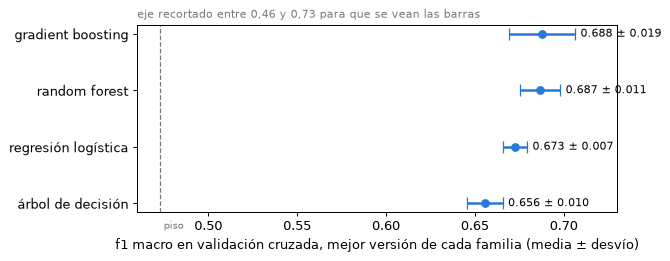

In [14]:
t = comparacion.drop("piso").sort_values("f1 con mejor umbral")

fig, ax = plt.subplots(figsize=(7.5, 3))
ax.errorbar(t["f1 con mejor umbral"], t.index, xerr=t["desvío"], fmt="o", capsize=5,
            color="#2a78d6", elinewidth=2)
for nombre, fila in t.iterrows():
    ax.text(fila["f1 con mejor umbral"] + fila["desvío"] + 0.003, nombre,
            f"{fila['f1 con mejor umbral']:.3f} ± {fila['desvío']:.3f}", va="center", fontsize=9)
ax.axvline(f1_piso.mean(), color="#7a7974", ls="--", lw=1)
ax.text(f1_piso.mean() + 0.002, -0.45, "piso", fontsize=8, color="#7a7974")
ax.set_xlim(0.46, 0.73)
ax.set_xlabel("f1 macro en validación cruzada, mejor versión de cada familia (media ± desvío)")
ax.set_title("eje recortado entre 0,46 y 0,73 para que se vean las barras", fontsize=9,
             color="#7a7974", loc="left")
plt.tight_layout()
plt.show()

**Se queda el random forest.** Ajustadas, las cuatro familias quedan así: gradient boosting 0,688 ±
0,019, random forest 0,687 ± 0,011, regresión logística 0,673 ± 0,007 y árbol 0,656 ± 0,010. La regla
es la de siempre: si el complejo no le gana al simple por más que el desvío, se queda el simple.

* **El random forest le gana a la logística por 0,014**, más que el desvío de los dos (0,011 y 0,007).
  Ésta vez el complejo sí gana.
* **El boosting le saca 0,015, pero su desvío es 0,019**: no le gana a la logística por más que su
  propio desvío. Su número se mueve más de un pedazo a otro.
* **Entre el bosque y el boosting hay una milésima: empate.** Nos quedamos con el que le gana al simple
  con claridad y es más estable: el bosque, con `max_depth=10` (como mucho 10 preguntas seguidas) y
  `max_features=0.3` (cada pregunta elige entre el 30 % de las columnas), y su umbral, 0,25.

La precision también sube: **0,41** en el bosque contra 0,36 en la logística, a un recall parecido
(0,49 contra 0,53).

Esto es lo que cambió con el barrido. Con los valores por defecto el bosque empataba con la logística
(0,675 contra 0,672); ajustado, se separa. Si hubiéramos elegido antes de ajustar, habríamos descartado
al modelo que mejor anda. La primera columna (umbral 0,5) vuelve a engañar: ahí el árbol parece el
mejor (0,600), porque sus probabilidades se animan más; con el umbral de cada uno, queda último.

In [15]:
# el elegido se guarda una vez y todo lo que sigue usa estas variables
ELEGIDO = "random forest"
PARAMS_ELEGIDOS = comparacion.loc[ELEGIDO, "hiperparámetros"]
UMBRAL_ELEGIDO = float(comparacion.loc[ELEGIDO, "mejor umbral"])


def modelo_elegido():
    return clone(FAMILIAS[ELEGIDO][0]).set_params(**PARAMS_ELEGIDOS)


def logistica_ajustada():
    return clone(FAMILIAS["regresión logística"][0]).set_params(
        **comparacion.loc["regresión logística", "hiperparámetros"])


print(f"{ELEGIDO}: {PARAMS_ELEGIDOS}, umbral {UMBRAL_ELEGIDO}")

random forest: {'max_depth': 10, 'max_features': 0.3, 'min_samples_leaf': 1}, umbral 0.25


## 6 · Qué pasaría si armáramos los pedazos al azar

La logística ajustada y el random forest elegido, validados de dos formas: por jugador (la nuestra) y
al azar, con `StratifiedKFold`, que puede dejar al mismo jugador de los dos lados.

In [16]:
from sklearn.model_selection import StratifiedKFold

al_azar = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
validaciones = {}
for nombre, hacer in [("regresión logística", logistica_ajustada), ("random forest", modelo_elegido)]:
    validaciones[(nombre, "por jugador")] = medir(armar(hacer()))
    validaciones[(nombre, "al azar")] = medir(armar(hacer()), validacion=al_azar)
pd.DataFrame(validaciones).T[["mejor umbral", "f1 con mejor umbral", "desvío"]].astype(float).round(3)

mejor umbral  f1 con mejor umbral  desvío
regresión logística por jugador          0.20                0.673   0.007
                    al azar              0.20                0.668   0.016
random forest       por jugador          0.25                0.687   0.011
                    al azar              0.25                0.686   0.013

In [17]:
# cuántos jugadores repetidos tiene el entrenamiento
repetidos = g_train.value_counts()
print(f"jugadores con más de un fichaje en el entrenamiento: {(repetidos > 1).sum():,} "
      f"de {len(repetidos):,} ({(repetidos > 1).mean():.1%})")

jugadores con más de un fichaje en el entrenamiento: 1,187 de 4,224 (28.1%)


**No cambió más que el desvío.** Al azar la logística da 0,668 y el bosque 0,686, contra 0,673 y
0,687 por jugador: diferencias de milésimas, dentro de la barra de error. Ni siquiera el bosque, que es
el modelo que más puede memorizar, gana algo con el mismo jugador de los dos lados, porque los fichajes
repetidos de un jugador son de temporadas distintas, con estadísticas y club de origen distintos: no hay
una fila repetida que reconocer.

Aun así mantenemos la partición por jugador. Es la que imita el uso —el modelo se va a usar con
jugadores que no vio— y no cuesta nada. Si hubiera habido fuga por jugador, el número al azar habría
salido más alto, sin ningún aviso; medirlo es la única forma de saber que acá no pasa.

## 7 · Lo que probamos para subir la precision

El barrido ya subió la precision (Sección 5). Con el modelo elegido probamos dos cosas más: cambiar
las columnas y cambiar el umbral.

### 7.1 Las columnas: con y sin cada bloque, y las candidatas que no habían entrado

Se saca un bloque por vez, o se agrega una columna, y se vuelve a medir con el mismo modelo y la misma
validación. Las candidatas son `fifa_puntos_prom` (la Hipótesis 1 había quedado inconclusa) y las que la
tabla de la Entrega 2 marcaba para entrar y no habían entrado. Lo que no sirvió también es evidencia.

In [18]:
SIN_ROJAS = tuple(c for c in STATS if c not in ("stat_duels_won_%", "stat_aerials_won_%",
                                                 "stat_dribbles_success_rate"))
variantes = {
    "modelo elegido": dict(),
    "sin los coeficientes UEFA del origen": dict(origen=()),
    "sin todo el club de origen (coeficientes, top 5, filial, europeo)": dict(origen=(), si_no=()),
    "sin las stats (sólo rol, origen, edad)": dict(stats=()),
    "sin las 3 stats que dieron rojo en la Entrega 2": dict(stats=SIN_ROJAS),
    "+ fifa_puntos_prom (Hipótesis 1)": dict(extra=("fifa_puntos_prom",)),
    "+ origen top 20 / top 50 de UEFA": dict(si_no=tuple(SI_NO) + ("club_origen_es_top_20",
                                                                     "club_origen_es_top_50")),
    "+ liga de origen": dict(categoricas_extra=("club_origen_liga",)),
    "+ nacionalidad": dict(categoricas_extra=("nacionalidad",),
                           si_no=tuple(SI_NO) + ("tiene_segunda_nacionalidad",)),
}
tabla_columnas = pd.DataFrame({nombre: medir(armar(modelo_elegido(), **kw))
                               for nombre, kw in variantes.items()}).T
tabla_columnas["diferencia"] = (tabla_columnas["f1 con mejor umbral"]
                                - tabla_columnas.loc["modelo elegido", "f1 con mejor umbral"])
tabla_columnas[["mejor umbral", "f1 con mejor umbral", "desvío", "diferencia", "precision",
                "recall"]].astype(float).round(3)

,mejor umbral,f1 con mejor umbral,desvío,diferencia,precision,recall
modelo elegido,0.25,0.687,0.011,0.000,0.407,0.491
sin los coeficientes UEFA del origen,0.25,0.670,0.017,-0.017,0.384,0.447
"sin todo el club de origen (coeficientes, top 5, filial, europeo)",0.25,0.647,0.013,-0.039,0.370,0.363
"sin las stats (sólo rol, origen, edad)",0.20,0.593,0.009,-0.093,0.235,0.447
sin las 3 stats que dieron rojo en la Entrega 2,0.25,0.679,0.015,-0.008,0.392,0.479
+ fifa_puntos_prom (Hipótesis 1),0.25,0.679,0.015,-0.007,0.395,0.476
+ origen top 20 / top 50 de UEFA,0.25,0.684,0.016,-0.003,0.402,0.486
+ liga de origen,0.25,0.684,0.013,-0.003,0.402,0.484
+ nacionalidad,0.25,0.684,0.015,-0.003,0.407,0.475


* **Las stats son lo que más pesa**: sin ellas el f1 cae 0,093, unas ocho veces el desvío, y la
  precision se desploma a 0,24. Es la Hipótesis 4, ahora dentro del modelo.
* **El club de origen aporta, y más que con la logística**: sin todo el bloque el f1 cae 0,039 (unos
  tres desvíos). Sin los coeficientes UEFA solos cae 0,017; con la logística caía 0,007. El bosque
  aprovecha lo que el coeficiente agrega **dentro** de las ligas, combinándolo con otras columnas.
* **Sacar las tres stats que dieron rojo no sirve** (−0,008, dentro del desvío): no estorban.
* **Ninguna candidata suma**: `fifa_puntos_prom` −0,007, y las de la Entrega 2 (origen top 20 / top 50,
  liga de origen, nacionalidad) −0,003 cada una. Lo que dicen ya está en el bloque del club de origen.
  Quedan afuera, y la Hipótesis 1 queda cerrada.

Por el lado de las columnas no hay precision para ganar: todas las variantes que suman o sacan algo
quedan con una precision igual o menor que la del modelo elegido (0,41).

### 7.2 El umbral: cuánta precision se compra con recall

Subir el umbral hace que el modelo diga «top 20» a menos jugadores: acierta más veces cuando lo dice
(sube la precision) pero encuentra a menos (baja el recall). El gráfico de la izquierda muestra ese
intercambio para el modelo elegido, umbral por umbral, en validación cruzada. El de la derecha es la
curva precision-recall de la Práctica 2 (6.3), la que informa con una clase chica, para el bosque y la
logística: cuanto más arriba, más precision a igual recall.

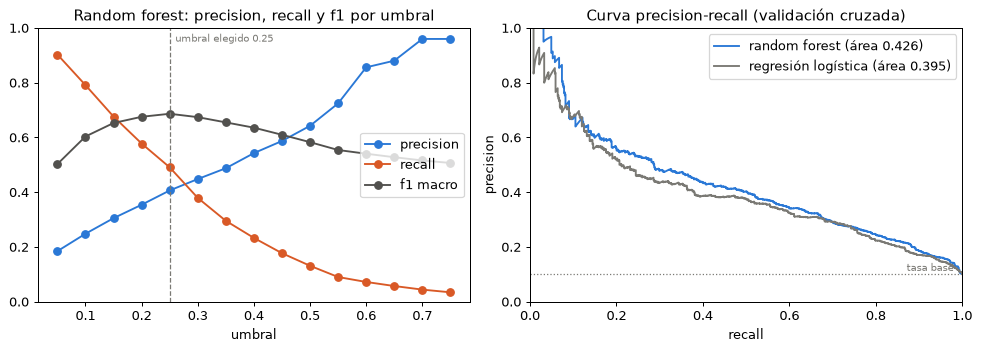

,f1 medio,desvío,precision,recall
umbral,,,,
0.20,0.676,0.011,0.354,0.578
0.25,0.687,0.011,0.407,0.491
0.30,0.674,0.013,0.448,0.379
0.35,0.655,0.008,0.488,0.296
0.40,0.636,0.013,0.543,0.233
0.50,0.583,0.020,0.643,0.131


In [19]:
from sklearn.metrics import precision_recall_curve, average_precision_score

tabla_umbral_elegido = por_umbral(armar(modelo_elegido()))
pedazos = list(cv.split(X_train, y_train, groups=g_train))
proba_cv = {nombre: cross_val_predict(armar(hacer()), X_train, y_train, groups=g_train, cv=pedazos,
                                      method="predict_proba", n_jobs=-1)[:, 1]
            for nombre, hacer in [("random forest", modelo_elegido),
                                  ("regresión logística", logistica_ajustada)]}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
tt = tabla_umbral_elegido
ax1.plot(tt.index, tt["precision"], marker="o", color="#2a78d6", label="precision")
ax1.plot(tt.index, tt["recall"], marker="o", color="#d95926", label="recall")
ax1.plot(tt.index, tt["f1 medio"], marker="o", color="#52514e", label="f1 macro")
ax1.axvline(UMBRAL_ELEGIDO, color="#7a7974", ls="--", lw=1)
ax1.text(UMBRAL_ELEGIDO + 0.01, 0.95, f"umbral elegido {UMBRAL_ELEGIDO:.2f}", fontsize=8, color="#7a7974")
ax1.set_xlabel("umbral"); ax1.set_ylim(0, 1); ax1.legend(loc="center right")
ax1.set_title("Random forest: precision, recall y f1 por umbral")
for (nombre, p), color in zip(proba_cv.items(), ["#2a78d6", "#7a7974"]):
    pr, rc, _ = precision_recall_curve(y_train, p)
    ax2.plot(rc, pr, color=color, label=f"{nombre} (área {average_precision_score(y_train, p):.3f})")
ax2.axhline(y_train.mean(), color="#7a7974", ls=":", lw=1)
ax2.text(0.98, y_train.mean() + 0.01, "tasa base", ha="right", fontsize=8, color="#7a7974")
ax2.set_xlabel("recall"); ax2.set_ylabel("precision"); ax2.set_xlim(0, 1); ax2.set_ylim(0, 1)
ax2.set_title("Curva precision-recall (validación cruzada)"); ax2.legend()
plt.tight_layout()
plt.show()

tt.loc[[0.2, 0.25, 0.3, 0.35, 0.4, 0.5], ["f1 medio", "desvío", "precision", "recall"]].round(3)

**El umbral elegido es el del mejor f1 macro: 0,25** (f1 0,687, precision 0,41, recall 0,49). Subirlo
compra precision con recall:

| Umbral | f1 macro | Precision | Recall |
|---|---|---|---|
| **0,25 (elegido)** | **0,687** | **0,41** | **0,49** |
| 0,30 | 0,674 | 0,45 | 0,38 |
| 0,40 | 0,636 | 0,54 | 0,23 |
| 0,50 | 0,583 | 0,64 | 0,13 |

Nos quedamos con 0,25 porque es la métrica que declaramos, que pesa igual perder a los que llegan y
llenar la lista de falsos. Si el uso pidiera una lista más corta y más segura —un scout que sólo puede
seguir a unos pocos—, esta tabla dice qué umbral usar y cuánto recall se pierde: con 0,40, uno de cada dos
señalados llega, pero encuentra a menos de uno de cada cuatro.

La curva de la derecha muestra el aumento de precision que sí se puede defender: **la curva del bosque
queda arriba de la de la logística en casi todo el recorrido** (área 0,426 contra 0,395). A igual
recall, el bosque tiene más precision. Esa mejora viene de un modelo mejor, no de mover la regla.

**Lo que probamos para subir la precision, todo junto:**

| Qué probamos | Precision (validación cruzada) | ¿Sirvió? |
|---|---|---|
| El barrido: de la logística al bosque ajustado | 0,36 → 0,41 | **Sí** |
| Agregar las candidatas (fifa, top 20/50, liga, nacionalidad) | 0,40 a 0,41 | No |
| Sacar las tres stats rojas | 0,39 | No |
| `class_weight` en vez del umbral (Sección 4) | — | No (0,613 contra 0,671 de f1) |
| Subir el umbral | hasta 0,64 | Sí, pero a costa de recall y de f1 |

## 8 · El modelo final, sobre el test (una sola vez)

Todo lo anterior se eligió con validación cruzada sobre el entrenamiento: la familia, sus
hiperparámetros, las columnas y el umbral. Recién ahora se entrena con todo el entrenamiento y se mira
el test.

In [20]:
final = armar(modelo_elegido()).fit(X_train, y_train)
proba_test = final.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= UMBRAL_ELEGIDO).astype(int)

pd.Series({"f1 macro en validación cruzada": comparacion.loc[ELEGIDO, "f1 con mejor umbral"],
           "f1 macro en el test": f1_score(y_test, pred_test, average="macro"),
           "precision de «top 20» en el test": precision_score(y_test, pred_test),
           "recall de «top 20» en el test": recall_score(y_test, pred_test),
           "piso en validación cruzada": f1_piso.mean()}).round(3)

f1 macro en validación cruzada      0.687
f1 macro en el test                 0.667
precision de «top 20» en el test    0.394
recall de «top 20» en el test       0.414
piso en validación cruzada          0.473
dtype: float64

In [21]:
from sklearn.metrics import classification_report

pd.DataFrame(classification_report(y_test, pred_test, target_names=["no top 20", "top 20"],
                                   output_dict=True)).T.round(3)

,precision,recall,f1-score,support
no top 20,0.933,0.927,0.930,1330.000
top 20,0.394,0.414,0.404,152.000
accuracy,0.874,0.874,0.874,0.874
macro avg,0.663,0.671,0.667,1482.000
weighted avg,0.877,0.874,0.876,1482.000


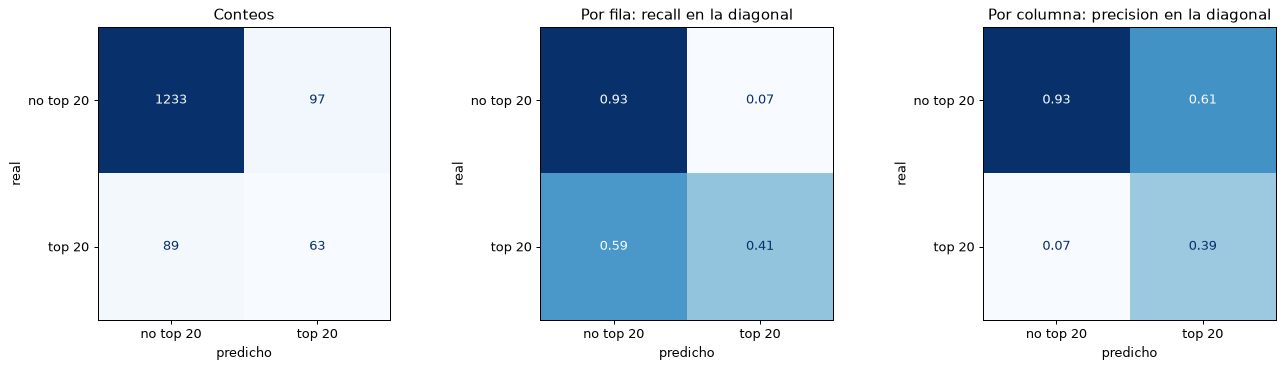

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (norm, titulo, fmt) in zip(axes, [(None, "Conteos", "d"),
                                          ("true", "Por fila: recall en la diagonal", ".2f"),
                                          ("pred", "Por columna: precision en la diagonal", ".2f")]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred_test, ax=ax, cmap="Blues", colorbar=False,
                                            normalize=norm, values_format=fmt,
                                            display_labels=["no top 20", "top 20"])
    ax.set_title(titulo); ax.set_xlabel("predicho"); ax.set_ylabel("real")
plt.tight_layout()
plt.show()

**0,667 en el test, contra 0,687 ± 0,011 en validación cruzada.** Queda un poco menos de dos desvíos
abajo, algo más que en la versión anterior, y tiene una explicación: esta vez elegimos entre 36
combinaciones, y quedarse con la mejor de muchas deja la validación cruzada un poco optimista (parte de
lo que la hace la mejor es suerte de los pedazos). Aun así queda arriba de lo que daba el test con la
logística (0,657), y nada de lo que se eligió se cambió después de mirarlo.

**La precision subió de 0,34 a 0,39, y el recall bajó de 0,49 a 0,41.** El bosque señala a menos
jugadores (160, contra 222 de la logística) y acierta más seguido cuando señala.

Las matrices, leídas:

* **Por fila** (recall): de los fichajes que **fueron** a un top 20, el modelo encuentra el 41 %. De
  los que no fueron, marca el 7 % como «top 20» (antes el 11 %).
* **Por columna** (precision): cuando el modelo dice «top 20», acierta el 39 %. Los falsos positivos
  (97) siguen siendo más que los aciertos (63), porque la clase «no» es nueve veces más grande, pero la
  brecha se achicó (antes eran 147 contra 75).

La accuracy (0,874) sigue **debajo** de contestar siempre «no» (0,897), aunque mejoró (0,849 antes).

### 8.1 Por qué se equivoca

Las probabilidades que el modelo le da a los que **fueron** a un top 20 y a los que **no**, en el test.
Si las dos distribuciones no se superpusieran, habría un umbral que no se equivoca nunca. El gráfico
muestra cuánto se superponen.

probabilidad mediana: 0.19 los que fueron, 0.04 los que no


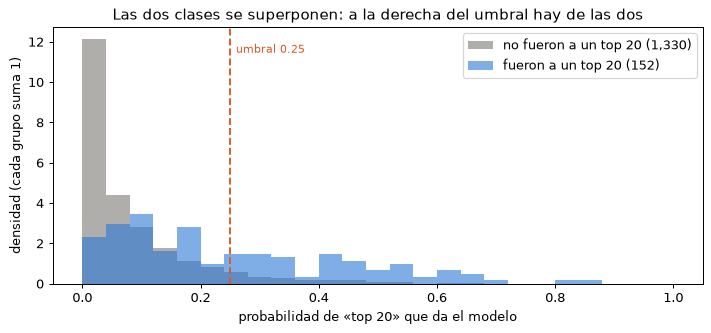

In [23]:
test = ana.iloc[idx_test].assign(proba=proba_test, pred=pred_test)
real = test["es_destino_top_20"].astype(bool)

fig, ax = plt.subplots(figsize=(8, 3.8))
cortes = np.linspace(0, 1, 26)
ax.hist(test.loc[~real, "proba"], bins=cortes, density=True, alpha=0.6, color="#7a7974",
        label=f"no fueron a un top 20 ({(~real).sum():,})")
ax.hist(test.loc[real, "proba"], bins=cortes, density=True, alpha=0.6, color="#2a78d6",
        label=f"fueron a un top 20 ({real.sum():,})")
ax.axvline(UMBRAL_ELEGIDO, color="#d95926", ls="--", lw=1.5)
ax.text(UMBRAL_ELEGIDO + 0.01, ax.get_ylim()[1] * 0.9, f"umbral {UMBRAL_ELEGIDO:.2f}", color="#d95926", fontsize=9)
ax.set_xlabel("probabilidad de «top 20» que da el modelo")
ax.set_ylabel("densidad (cada grupo suma 1)")
ax.set_title("Las dos clases se superponen: a la derecha del umbral hay de las dos")
ax.legend()
plt.tight_layout()
plt.show()

print(f"probabilidad mediana: {test.loc[real, 'proba'].median():.2f} los que fueron, "
      f"{test.loc[~real, 'proba'].median():.2f} los que no")

**El modelo ordena bien en promedio, pero las dos clases se superponen.** La probabilidad mediana de
los que fueron a un top 20 es 0,19; la de los que no, 0,04: la mayoría de los «no» quedan pegados a
cero. El problema son las colas. Hay «top 20» con probabilidad casi nula (los fichajes de Porto o Benfica
de la Sección 8.3) y «no» con probabilidad alta (los de la 8.2). A la derecha del umbral hay de las dos
clases, y correrlo saca falsos positivos pero también aciertos. Por eso el f1 no llega a 1: con lo que se
sabe antes del fichaje, una parte de los que van a un top 20 se parece a los que no van, y al revés.

### 8.2 Los falsos positivos: los que el modelo cree que debería haber comprado un club grande

Son los que bajan la precision: el modelo dijo «top 20» y no fueron. ¿Quiénes son, y a dónde fueron
en realidad? El destino **no** entra al modelo (es la respuesta); acá se usa sólo para leer el error
después.

In [24]:
vp = test[real & (test["pred"] == 1)]      # dijo top 20 y fueron
fp = test[~real & (test["pred"] == 1)]     # dijo top 20 y no fueron
vn = test[~real & (test["pred"] == 0)]     # dijo «no» y no fueron


def perfil(g):
    return {"cantidad": len(g), "probabilidad (mediana)": g["proba"].median(),
            "edad (mediana)": g["edad_al_fichaje"].median(),
            "minutos (mediana)": pd.to_numeric(g["stat_minutes"], errors="coerce").median(),
            "vienen de liga top 5": g["club_origen_liga_es_top5"].mean(),
            "su club está en el ranking UEFA": g["club_origen_coeficiente_uefa"].notna().mean()}


pd.DataFrame({"aciertos (top 20 bien dicho)": perfil(vp), "falsos positivos": perfil(fp),
              "verdaderos negativos": perfil(vn)}).round(2)

,aciertos (top 20 bien dicho),falsos positivos,verdaderos negativos
cantidad,63.00,97.00,1233.00
probabilidad (mediana),0.42,0.34,0.04
edad (mediana),25.00,25.00,25.00
minutos (mediana),3263.00,2988.00,1549.00
vienen de liga top 5,0.79,0.72,0.30
su club está en el ranking UEFA,0.95,0.84,0.58


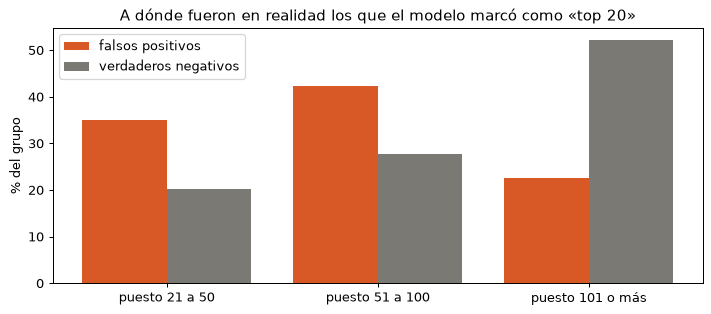

,falsos positivos,verdaderos negativos
club_destino_ranking_uefa,,
puesto 21 a 50,35.1,20.1
puesto 51 a 100,42.3,27.7
puesto 101 o más,22.7,52.1


In [25]:
# a dónde fueron de verdad: el puesto UEFA del club de destino
def puesto_destino(g):
    grupos = pd.cut(g["club_destino_ranking_uefa"], [20, 50, 100, 1000],
                    labels=["puesto 21 a 50", "puesto 51 a 100", "puesto 101 o más"])
    return grupos.value_counts(normalize=True).sort_index()


destinos = pd.DataFrame({"falsos positivos": puesto_destino(fp), "verdaderos negativos": puesto_destino(vn)})

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(destinos))
ax.bar(x - 0.2, destinos["falsos positivos"] * 100, 0.4, color="#d95926", label="falsos positivos")
ax.bar(x + 0.2, destinos["verdaderos negativos"] * 100, 0.4, color="#7a7974", label="verdaderos negativos")
ax.set_xticks(x, destinos.index)
ax.set_ylabel("% del grupo")
ax.set_title("A dónde fueron en realidad los que el modelo marcó como «top 20»")
ax.legend()
plt.tight_layout()
plt.show()
(destinos * 100).round(1)

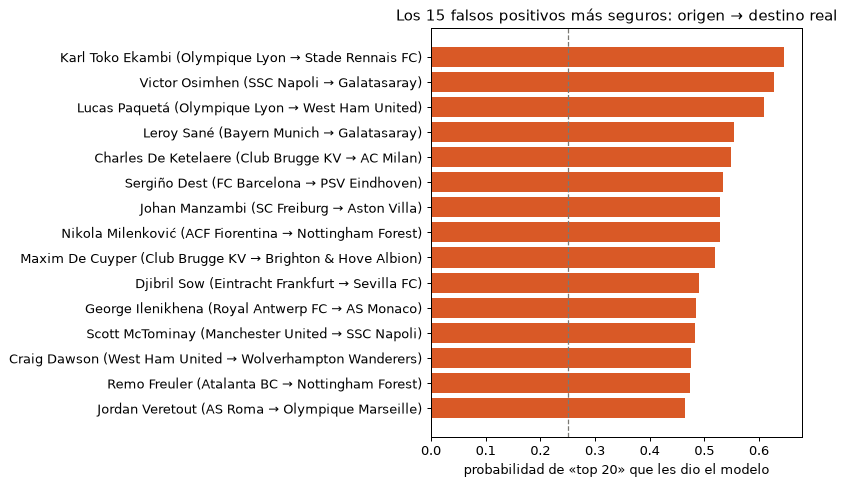

,nombre,edad_al_fichaje,grupo_posicion,club_origen,club_destino,club_destino_ranking_uefa,proba
3170,Karl Toko Ekambi,30.0,Delantero centro,Olympique Lyon,Stade Rennais FC,65,0.647
1409,Victor Osimhen,26.0,Delantero centro,SSC Napoli,Galatasaray,49,0.628
4271,Lucas Paquetá,25.0,Mediocampo ofensivo,Olympique Lyon,West Ham United,55,0.609
1417,Leroy Sané,29.0,Delantero extremo,Bayern Munich,Galatasaray,49,0.554
5528,Charles De Ketelaere,21.0,Mediocampo ofensivo,Club Brugge KV,AC Milan,34,0.548
4352,Sergiño Dest,23.0,Lateral,FC Barcelona,PSV Eindhoven,31,0.534
4649,Johan Manzambi,20.0,Mediocampo ofensivo,SC Freiburg,Aston Villa,40,0.529
6531,Nikola Milenković,26.0,Defensor central,ACF Fiorentina,Nottingham Forest,83,0.529
1199,Maxim De Cuyper,24.0,Lateral,Club Brugge KV,Brighton & Hove Albion,85,0.519
4066,Djibril Sow,26.0,Mediocampo ofensivo,Eintracht Frankfurt,Sevilla FC,27,0.491


In [26]:
# los 15 falsos positivos con más probabilidad: los que el modelo «compraría» para un top 20
top_fp = fp.sort_values("proba", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 5.5))
etiquetas = [f"{f.nombre} ({f.club_origen} → {f.club_destino})" for f in top_fp.itertuples()][::-1]
ax.barh(etiquetas, top_fp["proba"].values[::-1], color="#d95926")
ax.axvline(UMBRAL_ELEGIDO, color="#7a7974", ls="--", lw=1)
ax.set_xlabel("probabilidad de «top 20» que les dio el modelo")
ax.set_title("Los 15 falsos positivos más seguros: origen → destino real")
plt.tight_layout()
plt.show()

top_fp[["nombre", "edad_al_fichaje", "grupo_posicion", "club_origen", "club_destino",
        "club_destino_ranking_uefa", "proba"]].round(3)

**Los falsos positivos son, en su mayoría, jugadores que sí compró un club grande, sólo que no uno del
top 20.** Tienen el perfil de los aciertos: la misma edad (25), casi los mismos minutos (2.988 contra
3.263), y el 72 % viene de una liga top 5 (79 % los aciertos, 30 % los verdaderos negativos). Lo que los
separa de un acierto es el destino: el **35 %** fue a un club del puesto 21 al 50 de UEFA y el **42 %**
al 51 a 100. Entre los verdaderos negativos esos porcentajes son 20 % y 28 %, y la mitad fue a un club
del puesto 101 o más.

La lista lo muestra con nombres: **Scott McTominay** (Manchester United → Napoli, puesto 23), **Charles
De Ketelaere** (Brugge → Milan, 34), **Sergiño Dest** (Barcelona → PSV, 31), **Johan Manzambi**
(Freiburg → Aston Villa, 40), **Victor Osimhen** y **Leroy Sané** (Napoli y Bayern → Galatasaray, 49).
Son fichajes de club grande que quedaron a pocos puestos del corte. Para el modelo, el puesto 20 es una
línea que el perfil del jugador no ve: un jugador «de top 20» puede terminar en el 23 o en el 49 por
motivos que no están en los datos (la plata del comprador, una cláusula, la competencia por el mismo
jugador).

Esto dice dos cosas sobre la precision: que es baja en parte porque el objetivo corta una escala
continua en un punto fijo, y que muchos de sus errores son casi aciertos. Para un scout, que el modelo
señale a McTominay o a De Ketelaere no es una mala pista.

### 8.3 Los falsos negativos: los que llegaron a un top 20 y el modelo no vio

Son los que bajan el recall: fueron a un top 20 y el modelo dijo «no».

In [27]:
fn = test[real & (test["pred"] == 0)]      # fueron y el modelo dijo «no»

pd.DataFrame({"aciertos (encontrados)": perfil(vp), "falsos negativos (perdidos)": perfil(fn)}).round(2)

,aciertos (encontrados),falsos negativos (perdidos)
cantidad,63.00,89.00
probabilidad (mediana),0.42,0.11
edad (mediana),25.00,25.00
minutos (mediana),3263.00,1940.50
vienen de liga top 5,0.79,0.61
su club está en el ranking UEFA,0.95,0.73


                     encontrados  perdidos
club_destino                              
FC Porto                       3        13
Juventus FC                    5         9
AS Roma                        1        12
Chelsea FC                     3         9
Atalanta BC                    3         8
Atlético de Madrid             7         3
SL Benfica                     2         8
Tottenham Hotspur              4         4
Bayer 04 Leverkusen            3         5
Manchester United              5         2


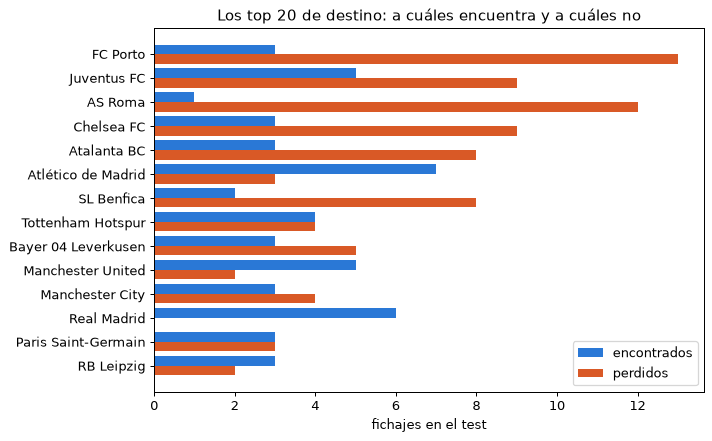

,nombre,edad_al_fichaje,grupo_posicion,club_origen,club_destino,stat_minutes,proba
6111,David Datro Fofana,20.0,Delantero centro,Molde FK,Chelsea FC,559.0,0.012
6638,Thiago Silva,41.0,Defensor central,Fluminense Football Club,FC Porto,1755.0,0.014
6606,David Carmo,22.0,Defensor central,SC Braga,FC Porto,1502.0,0.022
3401,Petar Musa,24.0,Delantero centro,Boavista FC,SL Benfica,2364.0,0.022
6607,Gabriel Veron,19.0,Delantero extremo,Sociedade Esportiva Palmeiras,FC Porto,524.0,0.025
6642,In-beom Hwang,29.0,Mediocampo ofensivo,Feyenoord Rotterdam,FC Porto,1339.0,0.026
1598,Adam Hlozek,19.0,Delantero centro,AC Sparta Praha,Bayer 04 Leverkusen,1403.0,0.027
6613,Iván Jaime,22.0,Mediocampo ofensivo,FC Famalicão,FC Porto,1878.0,0.029
6832,Marco Brescianini,25.0,Mediocampo ofensivo,Frosinone Calcio,Atalanta BC,1104.0,0.029
1030,Ola Solbakken,24.0,Delantero extremo,FK Bodø/Glimt,AS Roma,3470.0,0.032


In [28]:
# a qué clubes top 20 fueron los encontrados y los perdidos
clubes = pd.DataFrame({"encontrados": vp["club_destino"].value_counts(),
                       "perdidos": fn["club_destino"].value_counts()}).fillna(0).astype(int)
clubes = clubes.loc[clubes.sum(axis=1).sort_values(ascending=False).index].head(14)

fig, ax = plt.subplots(figsize=(8, 5))
y_pos = np.arange(len(clubes))[::-1]
ax.barh(y_pos + 0.2, clubes["encontrados"], 0.4, color="#2a78d6", label="encontrados")
ax.barh(y_pos - 0.2, clubes["perdidos"], 0.4, color="#d95926", label="perdidos")
ax.set_yticks(y_pos, clubes.index)
ax.set_xlabel("fichajes en el test")
ax.set_title("Los top 20 de destino: a cuáles encuentra y a cuáles no")
ax.legend()
plt.tight_layout()
plt.show()

print(clubes.head(10).to_string())
fn[["nombre", "edad_al_fichaje", "grupo_posicion", "club_origen", "club_destino",
    "stat_minutes", "proba"]].sort_values("proba").head(10).round(3)

**Los falsos negativos son el otro lado: fichajes a la parte de abajo del top 20 que no tienen perfil de
top 20.** Juegan menos (1.941 minutos de mediana contra 3.263 de los encontrados), vienen menos de una
liga top 5 (61 % contra 79 %) y más de clubes fuera del ranking UEFA (27 % contra 5 %). El gráfico
muestra a dónde van: el modelo encuentra los fichajes al Real Madrid (6 de 6), al Atlético (7 de 10) o al Manchester
United (5 de 7), y pierde casi
todos los del **Porto (13 de 16), la Roma (12 de 13), el Benfica (8 de 10)**, y buena parte de los de la
Juventus, el Chelsea y el Atalanta.

Desde el fútbol tiene sentido. Porto y Benfica están en el top 20 por sus resultados en copas europeas,
pero fichan como clubes medianos: compran en Portugal, Brasil o la liga de al lado, jugadores que se
parecen a cualquier otro fichaje de esas ligas. En la lista están David Carmo (Braga → Porto), Petar Musa
(Boavista → Benfica), Gabriel Veron (Palmeiras → Porto) o Thiago Silva, que con 41 años volvió de
Fluminense al Porto. También hay apuestas a futuro con pocos minutos, como David Datro Fofana (Molde →
Chelsea, 559 minutos). Nuestras columnas dicen lo que el jugador **fue** la temporada pasada y de dónde
viene; no dicen quién lo compra, y ése es justamente el dato que no podemos usar sin fuga.

**Precision y recall, juntos:** la precision la bajan jugadores con perfil de top 20 que terminan en el
puesto 21 a 100 (8.2); el recall lo bajan clubes del top 20 que compran jugadores sin ese perfil (8.3).
Los dos errores vienen del mismo lugar: el destino depende del comprador, y el comprador es la respuesta.

## 9 · En qué se apoya el modelo

Un random forest no tiene coeficientes. La consigna da la otra opción: la **importancia por
permutación** (Práctica 1, 5.4), que sirve para cualquier modelo. Se desordena una columna del test, se
vuelve a medir el f1 macro, y lo que cae es la importancia de esa columna. Se mide con nuestro umbral, no
con el 0,5 de `predict`. No tiene signo: dice cuánto usa el modelo cada columna, no hacia dónde empuja.

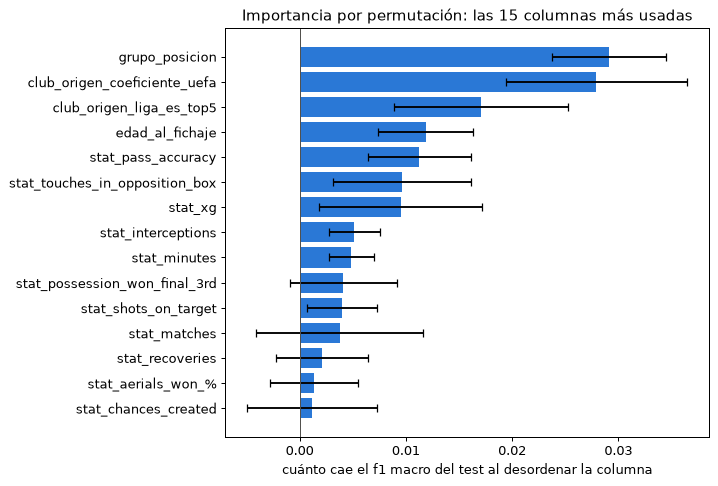

,caída del f1,desvío
grupo_posicion,0.0291,0.0054
club_origen_coeficiente_uefa,0.0279,0.0085
club_origen_liga_es_top5,0.0170,0.0082
edad_al_fichaje,0.0118,0.0045
stat_pass_accuracy,0.0113,0.0049
stat_touches_in_opposition_box,0.0096,0.0065
stat_xg,0.0095,0.0077
stat_interceptions,0.0051,0.0024
stat_minutes,0.0049,0.0021
stat_possession_won_final_3rd,0.0041,0.0050


In [29]:
from sklearn.inspection import permutation_importance


def f1_con_umbral(modelo, X, y):
    return f1_score(y, modelo.predict_proba(X)[:, 1] >= UMBRAL_ELEGIDO, average="macro")


pi = permutation_importance(final, X_test[COLUMNAS_MODELO], y_test, n_repeats=10,
                            scoring=f1_con_umbral, random_state=SEMILLA, n_jobs=-1)
importancia = pd.DataFrame({"caída del f1": pi.importances_mean, "desvío": pi.importances_std},
                           index=COLUMNAS_MODELO).sort_values("caída del f1", ascending=False)

top = importancia.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, top["caída del f1"], xerr=top["desvío"], color="#2a78d6", capsize=3)
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_xlabel("cuánto cae el f1 macro del test al desordenar la columna")
ax.set_title("Importancia por permutación: las 15 columnas más usadas")
plt.tight_layout()
plt.show()
importancia.head(15).round(4)

**Las que más usa el modelo son `grupo_posicion` (0,029), el coeficiente UEFA del club de origen
(0,028), `club_origen_liga_es_top5` (0,017) y la edad (0,012).** Después vienen las stats: precisión de
pase, toques en el área rival y xG.

Se leen con dos cuidados:

* **`grupo_posicion` pesa más de lo que parece.** Desordenarla no sólo cambia el rol: como la z de cada
  stat se calcula contra el rol (`ZPorRol`), también desordena contra quién se compara cada estadística.
  Su importancia es el rol y la forma de leer las stats, juntos.
* **Las columnas parecidas se reparten la importancia** (Práctica 1, 5.4). Liga top 5 y coeficiente del
  club dicen algo parecido, y cada stat sola pesa poco porque las otras la cubren. Una importancia baja
  no quiere decir que no sirva: sin las stats, todas juntas, el f1 cae 0,093 (Sección 7.1).

**¿Alguna es una fuga?** La revisamos con la pregunta de la Entrega 2: ¿existe antes del fichaje? La
posición, sí. El coeficiente y la liga son del club **de origen**, no se calculan con el destino (como sí
`traspaso_domestico` o `salto_ranking_uefa`, que salieron) y no traen la respuesta: el 19 % de quienes
vienen de una liga top 5 va a un top 20, y el 81 % no. Además el modelo no da «demasiado bien» (0,667 en
el test), que es la señal típica de una fuga.

### 9.1 Cómo usa la edad

La edad entra en años, sin cortar. ¿Qué forma le encontró el modelo? Para cada edad, la probabilidad
promedio que da el modelo (en validación cruzada, sin mirar el test) contra la tasa real de «top 20».

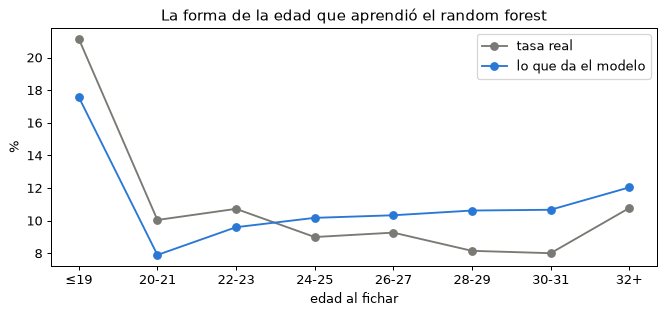

,fichajes,tasa real de top 20,probabilidad media del modelo
edad_al_fichaje,,,
≤19,383,0.211,0.176
20-21,886,0.100,0.079
22-23,1156,0.107,0.096
24-25,1100,0.090,0.102
26-27,917,0.093,0.103
28-29,650,0.082,0.106
30-31,437,0.080,0.107
32+,399,0.108,0.120


In [30]:
grupos_edad = pd.cut(X_train["edad_al_fichaje"], [15, 19, 21, 23, 25, 27, 29, 31, 45],
                     labels=["≤19", "20-21", "22-23", "24-25", "26-27", "28-29", "30-31", "32+"])
forma_edad = pd.DataFrame({
    "fichajes": grupos_edad.value_counts().sort_index(),
    "tasa real de top 20": y_train.groupby(grupos_edad, observed=True).mean(),
    "probabilidad media del modelo": pd.Series(proba_cv["random forest"], index=X_train.index)
                                       .groupby(grupos_edad, observed=True).mean()})

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(forma_edad.index.astype(str), forma_edad["tasa real de top 20"] * 100, marker="o",
        color="#7a7974", label="tasa real")
ax.plot(forma_edad.index.astype(str), forma_edad["probabilidad media del modelo"] * 100, marker="o",
        color="#2a78d6", label="lo que da el modelo")
ax.set_xlabel("edad al fichar"); ax.set_ylabel("%")
ax.set_title("La forma de la edad que aprendió el random forest")
ax.legend()
plt.tight_layout()
plt.show()
forma_edad.round(3)

**El modelo aprendió el salto de los más jóvenes.** A los de 19 años o menos les da 17,6 % de
probabilidad media, el doble que a los de 20 o 21 (7,9 %), como la tasa real (21,1 % contra 10,0 %). Es
la forma que encontró la Hipótesis 6, y que una logística, con una sola pendiente, no puede dibujar.

Lo que no reproduce es la leve baja desde los 28: ahí da un poco más que la tasa real (10,6 % contra
8,2 %), probablemente porque los mayores tienen más minutos, y los minutos empujan a favor. Con la edad
en tramos esa forma la habríamos decidido nosotros; numérica, la decidió el modelo.

## 10 · Cierre: las preguntas de la consigna

| Pregunta | Respuesta |
|---|---|
| **¿Por qué esa métrica?** | Con 10 % de positivos la accuracy premia contestar siempre «no» (0,90). El f1 macro pesa igual las dos clases, y el f1 castiga tanto perder jugadores que llegan como señalar a los que no. |
| **¿Cuánto le gana al piso?** | 0,473 → 0,687 en validación cruzada y 0,667 en el test. Para armar una lista corta de candidatos es útil: de cada cinco que señala, dos llegan a un top 20, y muchos de los otros terminan en clubes del puesto 21 a 100. Para decidir solo, no alcanza. |
| **¿Por qué la validación por jugador?** | Hay jugadores con más de un fichaje, y el modelo se va a usar con jugadores que no vio. Medimos qué pasaba al azar: no cambió más que el desvío (0,686 contra 0,687 en el bosque). La mantenemos porque imita el uso. |
| **¿Por qué ese modelo y no uno más simple?** | Ajustamos las cuatro familias antes de elegir. El random forest ajustado le gana a la logística por 0,014, más que el desvío de los dos; el boosting empata con el bosque pero no le gana a la logística por más que su desvío (0,019). |
| **¿Qué decidimos con el desbalance?** | Mover el umbral, elegido por validación cruzada: en la logística de referencia, 0,671 contra 0,613 de `class_weight`. El umbral final del bosque es 0,25. Cuesta accuracy (0,874 contra 0,897). |
| **¿Y la precision?** | El barrido la subió de 0,36 a 0,41 en validación (de 0,34 a 0,39 en el test). Agregar o sacar columnas no la mueve. Subir el umbral la compra con recall: con 0,40, 0,54 de precision y 0,23 de recall. |
| **¿Dónde se equivoca?** | Los falsos positivos son jugadores con perfil de top 20 que terminan en clubes del puesto 21 a 100 (McTominay al Napoli, De Ketelaere al Milan). Los falsos negativos son fichajes de Porto, Roma y Benfica, que compran jugadores sin ese perfil. |
| **¿En qué se apoya?** | El rol (y con él cómo se leen las stats), el coeficiente UEFA y la liga del club de origen, la edad (con el salto de los 19 años) y las stats. Ninguna es fuga: todas existen antes del fichaje y no usan el destino. |
| **¿Qué probamos y no anduvo?** | `fifa_puntos_prom` y las candidatas de la Entrega 2 (origen top 20/50, liga, nacionalidad), sacar las stats rojas, `class_weight`. En la Entrega 2 ya habían salido altura y pie (rojo). |

**Lo que queda para la Entrega 4.** El modelo final es el pipeline `final` (random forest ajustado) con
el umbral 0,25: recibe las columnas del jugador y del club de origen y devuelve la probabilidad de ir a un
top 20. Lo que no resuelve son los juveniles sin historial, que no están en esta población porque no
tienen estadísticas, y los fichajes que dependen del comprador más que del jugador.